# 03 · Election night: projecting races from partial county returns

**Replaying 2024's presidential count in seven states (NC, GA, PA, IA, FL, TX, MN), the projection's 90% intervals covered the final margin in about 97% of snapshots between 10% and 95% counted, with an average miss of about 1.7 points. Those settings were tuned on the same replays, though, and the hard case is real: in Florida and Texas, where the first counties in were the least like the last, the projection sat 3–4 points too Democratic for most of the night.** On Tuesday this runs inside the live dashboard (`scripts/live.py`; `scripts/election_night.py` is a plain terminal version), comparing each race's projection with Kalshi and Polymarket and logging the edge after fees. It reads only; it places no orders.

How a projection works (code in `src/midterms/live/`):
- **feeds.py** pulls county results from each state's official results site (NC, GA, IA, SC, MN, FL, TX, OH, plus Kansas, Michigan and Nebraska added on 2026-10-30; each checked against the 2024 general). The current list is in the [README's feeds table](../README.md#election-night).
- **baselines.py** gives each county its 2024 (here 2020) presidential margin, its expected turnout from 2022, and how much more Democratic each vote type (mail, early, Election Day) ran than the county in 2022.
- **project.py** estimates a statewide swing from counties that have finished counting (plus, weakly, partly counted ones), projects each unfinished county's remaining votes, and turns the projected margin and its uncertainty into P(D wins).

The replay uses only what was knowable before 2024: 2020 county margins as the baseline, 2022 vote-type leans, 2020 county turnout, and the final 2024 polling average as the prior. Counties are revealed in a plausible order: mail and early votes first, then Election Day with small counties tending to come in first (NC, GA, FL, TX, IA), or Election Day first with the two biggest counties' mail last (PA, MN).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from midterms.live import replay as RP, project as PJ

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.titlelocation": "left", "axes.titleweight": "bold"})
BLUE, RED, INK, GREY = "#2a78d6", "#e34948", "#52514e", "#8a8984"
rows = RP.rows_2024()
miss = pd.read_csv("../data/history/pres2024_state_miss.csv").set_index("state")
truth = rows.groupby(["state", "party"])["votes"].sum().unstack()
pd.DataFrame({"final 2024 margin (D−R)": (100 * (truth["D"] - truth["R"]) / truth.sum(axis=1)).round(2),
              "polling average (the prior)": miss.reindex(truth.index)["poll_d_margin"].round(2),
              "counties": rows.groupby("state")["fips"].nunique(),
              "vote types in the feed": rows.groupby("state")["vote_type"].apply(lambda s: ", ".join(sorted(set(s))))})

,final 2024 margin (D−R),polling average (the prior),counties,vote types in the feed
state,,,,
FL,-13.10,-6.58,67,total
GA,-2.31,-1.15,159,"early, election_day, mail, provisional"
IA,-13.21,-4.55,99,"election_day, mail"
MN,4.24,5.72,87,total
NC,-3.21,-1.20,100,"early, election_day, mail, provisional"
PA,-1.71,-0.22,67,"election_day, mail, provisional"
TX,-13.68,-7.50,254,"early, election_day"


## Two nights, replayed

North Carolina reports early and mail votes first; Florida reports county totals, small counties tending to finish first. The band is the projection's 90% interval; the dashed line is the vote counted so far.

Text(0.01, -0.03, 'Prior: final 2024 polling average. Baseline: 2020 county margins. One random reporting order per state.')

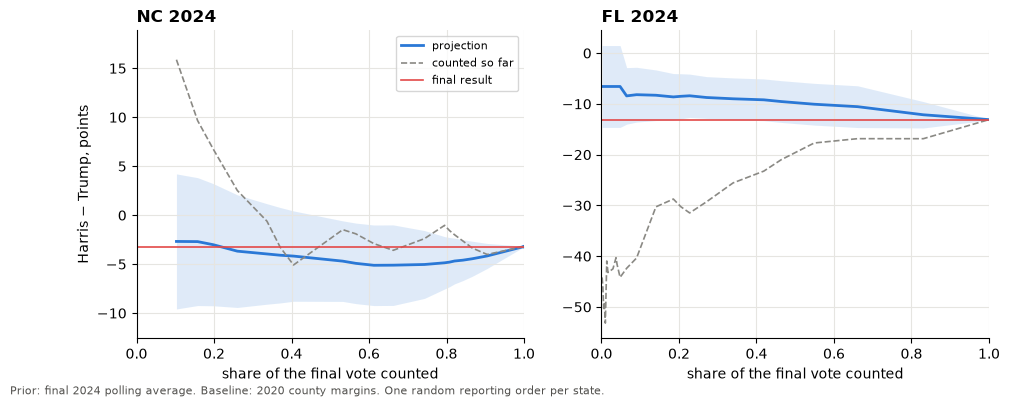

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (st, plan) in zip(axes, [("NC", "mail_first"), ("FL", "mail_first")]):
    d = rows[rows["state"] == st].drop(columns=["complete"], errors="ignore")
    r = RP.replay(d, st, prior=float(miss.loc[st, "poll_d_margin"]), plan=plan, steps=25, seed=1)
    ax.fill_between(r["share_in"], r["margin"] - 1.645 * r["sd"], r["margin"] + 1.645 * r["sd"], color=BLUE, alpha=0.15, lw=0)
    ax.plot(r["share_in"], r["margin"], color=BLUE, lw=2, label="projection")
    ax.plot(r["share_in"], r["counted_margin"], color=GREY, lw=1.2, ls="--", label="counted so far")
    ax.axhline(r["truth"].iloc[0], color=RED, lw=1.2, label="final result")
    lo = min(r["counted_margin"].min(), (r["margin"] - 1.645 * r["sd"]).min()) - 3
    hi = max(r["counted_margin"].max(), (r["margin"] + 1.645 * r["sd"]).max()) + 3
    ax.set(title=f"{st} 2024", xlabel="share of the final vote counted", xlim=(0, 1), ylim=(max(lo, -60), min(hi, 60)))
axes[0].set_ylabel("Harris − Trump, points")
axes[0].legend(loc="upper right", fontsize=8)
fig.text(0.01, -0.03, "Prior: final 2024 polling average. Baseline: 2020 county margins. One random reporting order per state.",
         fontsize=8, color=INK)

## Across seven states and eight reporting orders each

In [3]:
cal = RP.calibration(seeds=8, steps=10)
mid = cal[(cal["share_in"] >= 0.1) & (cal["share_in"] <= 0.95) & (cal["status"] == "projected")].copy()
mid["err"] = mid["truth"] - mid["margin"]
mid["z"] = mid["err"] / mid["sd"]
mid["counted"] = pd.cut(mid["share_in"], [0.1, 0.3, 0.5, 0.7, 0.85, 0.95])
by_share = mid.groupby("counted", observed=True).agg(
    snapshots=("z", "size"), rmse=("err", lambda e: np.sqrt((e ** 2).mean())), mean_sd=("sd", "mean"),
    covered_90=("z", lambda z: (z.abs() < 1.645).mean()), covered_50=("z", lambda z: (z.abs() < 0.674).mean()))
by_share.round(2)

,snapshots,rmse,mean_sd,covered_90,covered_50
counted,,,,,
"(0.1, 0.3]",100,2.40,3.51,0.93,0.74
"(0.3, 0.5]",91,2.11,2.81,0.99,0.63
"(0.5, 0.7]",73,2.01,2.52,1.00,0.44
"(0.7, 0.85]",83,1.98,1.70,0.96,0.29
"(0.85, 0.95]",15,0.89,0.99,1.00,0.07


In [4]:
mid.groupby("state").agg(snapshots=("z", "size"), mean_error=("err", "mean"), rmse=("err", lambda e: np.sqrt((e ** 2).mean())),
                         covered_90=("z", lambda z: (z.abs() < 1.645).mean())).round(2)

,snapshots,mean_error,rmse,covered_90
state,,,,
FL,33,-3.41,3.67,0.76
GA,56,0.52,0.61,1.00
IA,64,0.55,1.84,1.00
MN,48,-0.37,0.40,1.00
NC,56,1.17,1.32,1.00
PA,34,-0.92,1.39,1.00
TX,71,-3.17,3.28,0.96


Positive mean error = the result came in more Democratic than projected. Florida and Texas are the misses: the 2024 polls overstated Harris by 6–7 points there, the prior starts from those polls, and the counties that finish first (small, rural) swung less than the big counties that come last (Miami-Dade, the Rio Grande Valley), so the early data can't pull the projection far enough. The SD floor (`SD_SLOPE`, `SD_CAP` in project.py) widens the interval to cover that.

## How soon it called the winner

The share counted at which the eventual winner first reached 95% and stayed there, per state and reporting order.

In [5]:
def call_share(r):
    win_d = r["truth"].iloc[0] > 0
    p_win = r["p_d"] if win_d else 1 - r["p_d"]
    ok = (p_win >= 0.95).to_numpy()
    for i in range(len(ok)):
        if ok[i:].all():
            return r["share_in"].iloc[i]
    return np.nan


calls = cal.groupby(["state", "seed"]).apply(call_share, include_groups=False).rename("called_at").reset_index()
wrong = cal.groupby(["state", "seed"]).apply(lambda r: ((r["p_d"] >= 0.95) & (r["truth"] < 0) | (r["p_d"] <= 0.05) & (r["truth"] > 0)).any(),
                                             include_groups=False)
summary = calls.groupby("state")["called_at"].median().rename("median share counted at the call").to_frame()
summary["orders with a confident wrong call"] = wrong.groupby("state").sum()
summary.round(2)

,median share counted at the call,orders with a confident wrong call
state,,
FL,0.07,0
GA,0.77,0
IA,0.09,0
MN,0.19,0
NC,0.49,0
PA,0.99,0
TX,0.20,0


## Tuesday

*Updated 2026-10-30: the live dashboard replaced the terminal loop as the main tool, and Kansas, Michigan and Nebraska gained feeds.*

```bash
uv run python scripts/live.py                           # the dashboard, http://127.0.0.1:8765
uv run python scripts/live.py --replay-2024             # the same on a 2024 replay with a simulated market
uv run python scripts/election_night.py                 # plain terminal version, every 90s; Ctrl-C to stop
```

The dashboard shows every race's projection against Kalshi and Polymarket after Kalshi's fee, and P(Democratic Senate) and P(Democratic House) with every reported race at its projected margin (unreported races lean toward the swing seen so far). It logs to `data/live/<date>/` (model.csv, quotes.csv, events.csv); the terminal version logs `signals.csv` and `prices.csv`.

Still open:
- Iowa (Clarity 127077) and South Carolina (127300) have their 2026 ids; a changed id goes in `data/live/feed_ids.json`, no code edit. Texas's new statewide results site blocks AI crawlers, so Texas comes from seven counties' own results sites (Harris, Dallas, Tarrant, Denton, Fort Bend, Williamson, El Paso: 40% of the 2024 vote); Travis joins once its id is in `data/live/tx_sources.json`.
- Ohio's feed parser has only seen a zero-vote test file.
- Kansas's state results site is behind a bot check the tool doesn't try to get past, so it comes in through a browser bookmark (the page you have open is sent to the dashboard), with three county feeds as a backup. Michigan has five county feeds (34% of the 2024 vote).
- No usable feed for Wisconsin, Arizona, New Hampshire, New Jersey, New York, Maine or Alaska. Those races stay at their pre-election prior and move with the national swing seen so far.
- House districts are projected by uniform swing from their state's top race, not from their own counties (county baselines can't be split by district).

## Limits

- The uncertainty settings were tuned on these same 2024 replays: expect real coverage below the replay's ~97%.
- Vote-type leans come from 2022 and moved in 2024 (Republicans shifted into early voting); the model leans on finished counties for that reason, which makes it slow in states that report mail first.
- Late-arriving mail and provisional ballots after a county reports "complete" aren't modeled.
- Markets move within a couple of minutes of new returns (an assumption here, not measured; election night will measure it), so a visible edge is more likely a model error than an opportunity.